# PA4 - PySpark (Team 6, CineMatch)
## Task 1. Define and prepare the data

**Project goal:** CineMatch recommends movies based on who worked on them, so we need a clean table of IMDb credits that later steps can group, join, and rank.

**Question 1:** Which crew roles show up in the top 10 billing spots of IMDb titles, and how high are they billed on average? (same as PA3)

**Question 2:** How does the mix of roles in the top 10 billing spots change across release eras?

**One row:** one credit (one person in one billing position on one title).
**Key:** (title_id, billing_order)

**Prepared Parquet columns:** title_id (string), billing_order (int), person_id (string), role_category (string), is_top10 (boolean, derived from billing_order <= 10).

**Lookup columns used in Task 2:** tconst (string) and start_year (int, release year; NULL if unknown).

In [32]:
!pip install -q pyspark

In [33]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import csv

spark = (SparkSession.builder
           .appName("CS131-PA4-Team6")
           .master("local[2]")
           .getOrCreate())

In [34]:
!git clone -q https://github.com/sjsu-cs131-f26/CineMatch-Netflix-Movies.git

BASE = "CineMatch-Netflix-Movies/pa4"
INPUT_PATH = f"{BASE}/data/sample/principals_sample.tsv"
PARQUET_PATH = f"{BASE}/work/prepared_credits.parquet"

checks = []
def record(check, value, note=""):
    checks.append([check, value, note])
    print(check, "=", value)

fatal: destination path 'CineMatch-Netflix-Movies' already exists and is not an empty directory.


In [35]:
schema = ("tconst STRING, ordering INT, nconst STRING, "
          "category STRING, job STRING, characters STRING")

raw = (spark.read
       .option("header", True)
       .option("sep", "\t")
       .schema(schema)
       .csv(INPUT_PATH))

raw.printSchema()
raw.show(5)
record("rows read", raw.count())

root
 |-- tconst: string (nullable = true)
 |-- ordering: integer (nullable = true)
 |-- nconst: string (nullable = true)
 |-- category: string (nullable = true)
 |-- job: string (nullable = true)
 |-- characters: string (nullable = true)

+---------+--------+---------+---------------+--------------------+----------+
|   tconst|ordering|   nconst|       category|                 job|characters|
+---------+--------+---------+---------------+--------------------+----------+
|tt0000001|       1|nm1588970|           self|                  \N|  ["Self"]|
|tt0000001|       2|nm0005690|       director|                  \N|        \N|
|tt0000001|       3|nm0005690|       producer|            producer|        \N|
|tt0000001|       4|nm0374658|cinematographer|director of photo...|        \N|
|tt0000002|       1|nm0721526|       director|                  \N|        \N|
+---------+--------+---------+---------------+--------------------+----------+
only showing top 5 rows
rows read = 1000


In [36]:
credits = raw.select(
    F.col("tconst").alias("title_id"),
    F.col("ordering").alias("billing_order"),
    F.col("nconst").alias("person_id"),
    F.col("category").alias("role_category"))

credits.printSchema()

root
 |-- title_id: string (nullable = true)
 |-- billing_order: integer (nullable = true)
 |-- person_id: string (nullable = true)
 |-- role_category: string (nullable = true)



In [37]:
missing = credits.filter(
    F.col("title_id").isNull() |
    F.col("person_id").isNull() |
    F.col("billing_order").isNull() |
    (F.col("billing_order") < 1) |
    F.col("role_category").isNull() |
    (F.col("role_category") == "\\N"))

record("rows with a missing or invalid required value", missing.count(),
       "excluded: a credit with no ID, position, or role can't be grouped or ranked")

valid = credits.filter(
    F.col("title_id").isNotNull() &
    F.col("person_id").isNotNull() &
    (F.col("billing_order") >= 1) &
    F.col("role_category").isNotNull() &
    (F.col("role_category") != "\\N"))

record("rows kept", valid.count())

rows with a missing or invalid required value = 0
rows kept = 1000


In [38]:
repeated = (valid.groupBy("title_id", "billing_order").count()
            .filter(F.col("count") > 1))

record("repeated (title_id, billing_order) keys", repeated.count(),
       "not removed: two rows with the same key could be different people")

repeated (title_id, billing_order) keys = 0


In [39]:
prepared = valid.withColumn("is_top10", F.col("billing_order") <= 10)

top10 = prepared.filter(F.col("is_top10")).count()
record("credits in the top 10 billing spots", top10)
prepared.show(5)

credits in the top 10 billing spots = 969
+---------+-------------+---------+---------------+--------+
| title_id|billing_order|person_id|  role_category|is_top10|
+---------+-------------+---------+---------------+--------+
|tt0000001|            1|nm1588970|           self|    true|
|tt0000001|            2|nm0005690|       director|    true|
|tt0000001|            3|nm0005690|       producer|    true|
|tt0000001|            4|nm0374658|cinematographer|    true|
|tt0000002|            1|nm0721526|       director|    true|
+---------+-------------+---------+---------------+--------+
only showing top 5 rows


In [41]:
prepared.write.mode("overwrite").parquet(PARQUET_PATH)
restored = spark.read.parquet(PARQUET_PATH)

restored.printSchema()
record("Parquet read-back rows", restored.count(), "should equal rows kept")
record("Parquet read-back top-10 credits", restored.filter(F.col("is_top10")).count(),
       "should equal credits in the top 10 billing spots")

record("prepared column types", str(prepared.dtypes),
       "title_id string, billing_order int, person_id string, role_category string, is_top10 boolean")

record("missing title_id after cleaning", prepared.filter(F.col("title_id").isNull()).count(), "should be 0")
record("missing role_category after cleaning", prepared.filter(F.col("role_category").isNull()).count(), "should be 0")
record("min billing_order", prepared.agg(F.min("billing_order")).collect()[0][0], "must be >= 1")
record("max billing_order", prepared.agg(F.max("billing_order")).collect()[0][0])

roles = prepared.groupBy("role_category").count().orderBy("role_category")
record("distinct role_category values", roles.count(),
       "; ".join(r["role_category"] for r in roles.collect()))

record("Parquet schema matches prepared", str(restored.dtypes == prepared.dtypes),
       "same column names and types after read-back")
record("Parquet read-back distinct titles", restored.groupBy("title_id").count().count(),
       "project check: should equal titles before saving (" +
       str(prepared.groupBy("title_id").count().count()) + ")")

root
 |-- title_id: string (nullable = true)
 |-- billing_order: integer (nullable = true)
 |-- person_id: string (nullable = true)
 |-- role_category: string (nullable = true)
 |-- is_top10: boolean (nullable = true)

Parquet read-back rows = 1000
Parquet read-back top-10 credits = 969
prepared column types = [('title_id', 'string'), ('billing_order', 'int'), ('person_id', 'string'), ('role_category', 'string'), ('is_top10', 'boolean')]
missing title_id after cleaning = 0
missing role_category after cleaning = 0
min billing_order = 1
max billing_order = 19
distinct role_category values = 10
Parquet schema matches prepared = True
Parquet read-back distinct titles = 455


In [42]:
top10_df = restored.filter(F.col("is_top10") == True)

analysis1 = (top10_df.groupBy("role_category").agg(
        F.count("*").alias("credit_count"),
        F.format_string("%.2f", F.avg("billing_order")).alias("avg_billing_order")
    )
    .withColumn("role_rank", F.row_number().over(Window.orderBy(
                F.desc("credit_count"),
                F.asc("role_category")
            )
        )
    ).select("role_rank", "role_category", "credit_count", "avg_billing_order")
    .orderBy("role_rank"))

analysis1.show()

+---------+-------------------+------------+-----------------+
|role_rank|      role_category|credit_count|avg_billing_order|
+---------+-------------------+------------+-----------------+
|        1|           director|         418|             1.50|
|        2|              actor|         156|             2.55|
|        3|           producer|         140|             3.04|
|        4|    cinematographer|         102|             3.56|
|        5|            actress|          64|             2.27|
|        6|               self|          40|             2.15|
|        7|             writer|          39|             3.23|
|        8|           composer|           5|             3.20|
|        9|             editor|           3|             5.33|
|       10|production_designer|           2|             6.50|
+---------+-------------------+------------+-----------------+



In [43]:
!mkdir -p CineMatch-Netflix-Movies/pa4/out

In [44]:
analysis1_pd = analysis1.toPandas()

analysis1_pd["avg_billing_order"] = analysis1_pd[
    "avg_billing_order"
].map(lambda x: f"{float(x):.2f}")

analysis1_pd.to_csv("CineMatch-Netflix-Movies/pa4/out/analysis_1.csv",index=False)
!cat CineMatch-Netflix-Movies/pa4/out/analysis_1.csv

role_rank,role_category,credit_count,avg_billing_order
1,director,418,1.50
2,actor,156,2.55
3,producer,140,3.04
4,cinematographer,102,3.56
5,actress,64,2.27
6,self,40,2.15
7,writer,39,3.23
8,composer,5,3.20
9,editor,3,5.33
10,production_designer,2,6.50


In [45]:
lookup_schema = (
    "tconst STRING, title_type STRING, primary_title STRING, "
    "original_title STRING, is_adult INT, start_year STRING, "
    "end_year STRING, runtime_minutes STRING, genres STRING"
)

lookup = (spark.read
         .option("header", True)
         .option("sep", "\t")
         .schema(lookup_schema)
         .csv(f"{BASE}/data/sample/title_basics_lookup.tsv"))
lookup.select("tconst", "start_year").show(5)

+---------+----------+
|   tconst|start_year|
+---------+----------+
|tt0000001|      1894|
|tt0000002|      1892|
|tt0000003|      1892|
|tt0000004|      1892|
|tt0000005|      1893|
+---------+----------+
only showing top 5 rows


In [46]:
top10_with_year = (top10_df.join(
        lookup,
        top10_df.title_id == lookup.tconst,
        "inner").select(
        top10_df["*"],
        lookup["start_year"].cast("int").alias("start_year")))

top10_with_year.show()

+---------+-------------+---------+---------------+--------+----------+
| title_id|billing_order|person_id|  role_category|is_top10|start_year|
+---------+-------------+---------+---------------+--------+----------+
|tt0000001|            4|nm0374658|cinematographer|    true|      1894|
|tt0000001|            3|nm0005690|       producer|    true|      1894|
|tt0000001|            2|nm0005690|       director|    true|      1894|
|tt0000001|            1|nm1588970|           self|    true|      1894|
|tt0000002|            2|nm1335271|       composer|    true|      1892|
|tt0000002|            1|nm0721526|       director|    true|      1892|
|tt0000003|            6|nm5442200|         editor|    true|      1892|
|tt0000003|            5|nm1335271|       composer|    true|      1892|
|tt0000003|            4|nm0721526|       producer|    true|      1892|
|tt0000003|            3|nm1770680|       producer|    true|      1892|
|tt0000003|            2|nm0721526|         writer|    true|    

In [47]:
top10_with_era = (top10_with_year.withColumn("release_era",
        F.when(F.col("start_year").isNull(), "unknown")
         .when(F.col("start_year") < 1980, "before_1980")
         .when(F.col("start_year") <= 1999, "1980_1999")
         .when(F.col("start_year") <= 2009, "2000_2009")
         .when(F.col("start_year") <= 2019, "2010_2019")
         .otherwise("2020_or_later")).withColumn(
        "era_order",
        F.when(F.col("release_era") == "before_1980", 1)
         .when(F.col("release_era") == "1980_1999", 2)
         .when(F.col("release_era") == "2000_2009", 3)
         .when(F.col("release_era") == "2010_2019", 4)
         .when(F.col("release_era") == "2020_or_later", 5)
         .otherwise(6)))

In [48]:
duplicate_lookup_keys = (lookup.groupBy("tconst").count().filter(F.col("count") > 1))

print("Duplicate lookup keys:", duplicate_lookup_keys.count())

unmatched_credits = (top10_df.join(lookup, top10_df.title_id == lookup.tconst, "left_anti"))

print("Top-10 rows before join:", top10_df.count())
print("Unmatched top-10 rows:", unmatched_credits.count())
print("Rows after join:", top10_with_era.count())

Duplicate lookup keys: 0
Top-10 rows before join: 969
Unmatched top-10 rows: 0
Rows after join: 969


In [49]:
analysis2 = (top10_with_era.groupBy("era_order", "release_era", "role_category").agg(
        F.count("*").alias("credit_count"),
        F.format_string("%.2f", F.avg("billing_order")).alias("avg_billing_order"))
    .orderBy(
        F.asc("era_order"),
        F.desc("credit_count"),
        F.asc("role_category"))
    .select(
        "release_era",
        "role_category",
        "credit_count",
        "avg_billing_order"))

analysis2.show()

+-----------+-------------------+------------+-----------------+
|release_era|      role_category|credit_count|avg_billing_order|
+-----------+-------------------+------------+-----------------+
|before_1980|           director|         418|             1.50|
|before_1980|              actor|         156|             2.55|
|before_1980|           producer|         140|             3.04|
|before_1980|    cinematographer|         102|             3.56|
|before_1980|            actress|          64|             2.27|
|before_1980|               self|          40|             2.15|
|before_1980|             writer|          39|             3.23|
|before_1980|           composer|           5|             3.20|
|before_1980|             editor|           3|             5.33|
|before_1980|production_designer|           2|             6.50|
+-----------+-------------------+------------+-----------------+



In [50]:
analysis2_pd = analysis2.toPandas()

analysis2_pd["avg_billing_order"] = analysis2_pd[
    "avg_billing_order"
].map(lambda x: f"{float(x):.2f}")

analysis2_pd.to_csv("CineMatch-Netflix-Movies/pa4/out/analysis_2.csv", index=False)
!cat CineMatch-Netflix-Movies/pa4/out/analysis_2.csv

release_era,role_category,credit_count,avg_billing_order
before_1980,director,418,1.50
before_1980,actor,156,2.55
before_1980,producer,140,3.04
before_1980,cinematographer,102,3.56
before_1980,actress,64,2.27
before_1980,self,40,2.15
before_1980,writer,39,3.23
before_1980,composer,5,3.20
before_1980,editor,3,5.33
before_1980,production_designer,2,6.50


## Task 2 Findings

Analysis 1 shows that directors have the most top 10 billing credits in the sample with 418 credits. Actors are second with 156 credits, then producers with 140 credits.

The PA3 committed result left out composer, editor, and production_designer, even though the PA3 SQL grouped all role categories. The PA4 analysis follows the executable PA3 query rules and so it includes those categories.


Analysis 2 groups the top 10 credits by release era. In the committed sample, all 969 top 10 credits belong to the `before_1980` era, so the sample doesn't contain enough era groups to show a change over time. Within this era, directors lead with 418 credits, then actors with 156 and producers with 140.

One limitation is that the committed lookup sample does not contain titles from later release eras. Therefore, the sample can't show how role patterns change over time. The full IMDb dataset should be used for the final release era comparison.

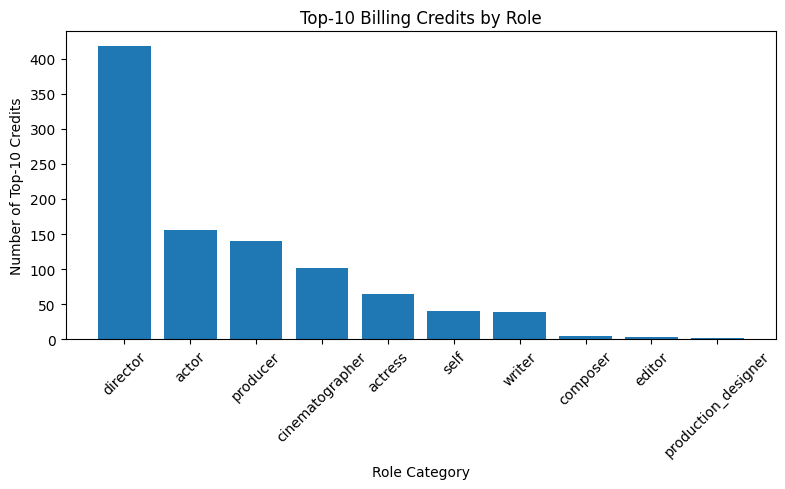

In [51]:
import matplotlib.pyplot as plt

analysis1_pd = analysis1.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(analysis1_pd["role_category"],analysis1_pd["credit_count"])

plt.xlabel("Role Category")
plt.ylabel("Number of Top-10 Credits")
plt.title("Top-10 Billing Credits by Role")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("CineMatch-Netflix-Movies/pa4/out/analysis_1_chart.png")
plt.show()

In [52]:
!cat CineMatch-Netflix-Movies/pa4/out/quality_checks.csv

check,value,note
rows read,1000,
rows with a missing or invalid required value,0,"excluded: a credit with no ID, position, or role can't be grouped or ranked"
rows kept,1000,
"repeated (title_id, billing_order) keys",0,not removed: two rows with the same key could be different people
credits in the top 10 billing spots,969,
Parquet read-back rows,1000,should equal rows kept
Parquet read-back top-10 credits,969,should equal credits in the top 10 billing spots


In [53]:
with open(f"{BASE}/out/quality_checks.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["check", "value", "note"])
    writer.writerows(checks)

from google.colab import files
files.download(f"{BASE}/out/quality_checks.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
sample_fraction = 0.3
sample_seed = 131

source_rows = restored.count()

dev_sample = restored.sample(withReplacement=False, fraction=sample_fraction, seed=sample_seed)
dev_sample = dev_sample.cache()
sample_rows = dev_sample.count()

observed_fraction = sample_rows / source_rows

record("population sampled", source_rows)
record("sample fraction requested", sample_fraction)
record("sample seed", sample_seed)
record("sample rows", sample_rows)
record("observed sample fraction", round(observed_fraction, 4))

population sampled = 1000
sample fraction requested = 0.3
sample seed = 131
sample rows = 299
observed sample fraction = 0.299


In [55]:
comparison_rows = []
missing_groups = []

for column in ["role_category", "is_top10"]:
    source_counts = {}
    for row in restored.groupBy(column).count().collect():
        source_counts[str(row[column])] = row["count"]

    sample_counts = {}
    for row in dev_sample.groupBy(column).count().collect():
        sample_counts[str(row[column])] = row["count"]

    for value in sorted(source_counts):
        source_count = source_counts[value]
        source_percent = round(100 * source_count / source_rows, 2)

        if value in sample_counts:
            sample_count = sample_counts[value]
        else:
            sample_count = 0
            missing_groups.append(column + "=" + value)

        sample_percent = round(100 * sample_count / sample_rows, 2)
        difference = round(sample_percent - source_percent, 2)

        comparison_rows.append([column, value, source_count, source_percent,
                                sample_count, sample_percent, difference])

header = ["group_column", "group_value", "source_count", "source_percent",
          "sample_count", "sample_percent", "percent_difference"]

print(header)
for row in comparison_rows:
    print(row)

record("groups missing from sample", len(missing_groups), ", ".join(missing_groups))

with open(f"{BASE}/out/sample_comparison.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(header)
    writer.writerows(comparison_rows)

['group_column', 'group_value', 'source_count', 'source_percent', 'sample_count', 'sample_percent', 'percent_difference']
['role_category', 'actor', 161, 16.1, 46, 15.38, -0.72]
['role_category', 'actress', 64, 6.4, 20, 6.69, 0.29]
['role_category', 'cinematographer', 107, 10.7, 38, 12.71, 2.01]
['role_category', 'composer', 12, 1.2, 4, 1.34, 0.14]
['role_category', 'director', 423, 42.3, 121, 40.47, -1.83]
['role_category', 'editor', 3, 0.3, 1, 0.33, 0.03]
['role_category', 'producer', 143, 14.3, 46, 15.38, 1.08]
['role_category', 'production_designer', 3, 0.3, 0, 0.0, -0.3]
['role_category', 'self', 40, 4.0, 12, 4.01, 0.01]
['role_category', 'writer', 44, 4.4, 11, 3.68, -0.72]
['is_top10', 'False', 31, 3.1, 8, 2.68, -0.42]
['is_top10', 'True', 969, 96.9, 291, 97.32, 0.42]
groups missing from sample = 1


In [56]:
import duckdb

duck_rows = duckdb.sql(f"""
    SELECT category, COUNT(*) AS credit_count, ROUND(AVG(ordering::INT), 2) AS avg_billing_order
    FROM read_csv('{INPUT_PATH}', delim='\\t', header=true, quote='', all_varchar=true)
    WHERE ordering::INT BETWEEN 1 AND 10 AND category <> '\\\\N'
    GROUP BY category
""").fetchall()

duck_results = {}
for role, count, average in duck_rows:
    duck_results[role] = (count, float(average))

all_match = True
csv_rows = 0

with open(f"{BASE}/out/analysis_1.csv") as f:
    for row in csv.DictReader(f):
        csv_rows = csv_rows + 1
        role = row["role_category"]

        if role not in duck_results:
            all_match = False
            print("missing in duckdb:", role)
        else:
            duck_count = duck_results[role][0]
            duck_average = duck_results[role][1]
            if int(row["credit_count"]) != duck_count or abs(float(row["avg_billing_order"]) - duck_average) > 0.01:
                all_match = False
                print("mismatch:", role, row, duck_results[role])

if csv_rows != len(duck_results):
    all_match = False

record("analysis 1 rows (csv / duckdb)", str(csv_rows) + " / " + str(len(duck_results)))
record("analysis 1 verified with duckdb", all_match)

analysis 1 rows (csv / duckdb) = 10 / 10
analysis 1 verified with duckdb = True


In [57]:
dev_sample.write.mode("overwrite").parquet(f"{BASE}/out/handoff/dev_sample_parquet")
restored.write.mode("overwrite").parquet(f"{BASE}/out/handoff/prepared_credits_parquet")

dev_sample.toPandas().to_csv(f"{BASE}/out/dev_sample.csv", index=False)

check_back = spark.read.parquet(f"{BASE}/out/handoff/dev_sample_parquet").count()
record("dev sample read-back rows", check_back)

with open(f"{BASE}/out/quality_checks.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["check", "value", "note"])
    writer.writerows(checks)

from google.colab import files
files.download(f"{BASE}/out/sample_comparison.csv")
files.download(f"{BASE}/out/quality_checks.csv")
files.download(f"{BASE}/out/dev_sample.csv")

dev sample read-back rows = 299


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
import time
import os
import duckdb

input_bytes = os.path.getsize(INPUT_PATH)
input_rows = raw.count()

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("DuckDB version:", duckdb.__version__)
print("Input file:", INPUT_PATH)
print("Input rows:", input_rows)
print("Input bytes:", input_bytes)

Spark version: 4.0.5
Spark master: local[2]
DuckDB version: 1.3.2
Input file: CineMatch-Netflix-Movies/pa4/data/sample/principals_sample.tsv
Input rows: 1000
Input bytes: 41464


In [59]:
def spark_analysis_1():
    data = (spark.read
            .option("header", True)
            .option("sep", "\t")
            .schema(schema)
            .csv(INPUT_PATH))
    result = (data
              .filter(F.col("tconst").isNotNull() & F.col("nconst").isNotNull())
              .filter((F.col("ordering") >= 1) & (F.col("ordering") <= 10))
              .filter(F.col("category").isNotNull() & (F.col("category") != "\\N"))
              .groupBy("category")
              .agg(F.count("*").alias("credit_count"),
                   F.round(F.avg("ordering"), 2).alias("avg_billing_order"))
              .orderBy(F.col("credit_count").desc(), "category"))
    rows = []
    for row in result.collect():
        rows.append([row["category"], row["credit_count"], float(row["avg_billing_order"])])
    return rows


def duckdb_analysis_1():
    result = duckdb.sql(f"""
        SELECT category, COUNT(*) AS credit_count, ROUND(AVG(ordering), 2) AS avg_billing_order
        FROM read_csv('{INPUT_PATH}', delim='\\t', header=true, quote='',
                      columns={{'tconst': 'VARCHAR', 'ordering': 'INTEGER', 'nconst': 'VARCHAR',
                               'category': 'VARCHAR', 'job': 'VARCHAR', 'characters': 'VARCHAR'}})
        WHERE tconst IS NOT NULL AND nconst IS NOT NULL
          AND ordering BETWEEN 1 AND 10
          AND category IS NOT NULL AND category <> '\\N'
        GROUP BY category
        ORDER BY credit_count DESC, category
    """).fetchall()
    rows = []
    for category, count, average in result:
        rows.append([category, count, float(average)])
    return rows


spark_rows = spark_analysis_1()
duck_rows = duckdb_analysis_1()

results_match = len(spark_rows) == len(duck_rows)
for i in range(len(spark_rows)):
    spark_row = spark_rows[i]
    duck_row = duck_rows[i]
    if spark_row[0] != duck_row[0] or spark_row[1] != duck_row[1] or abs(spark_row[2] - duck_row[2]) > 0.01:
        results_match = False
        print("mismatch:", spark_row, duck_row)

print("Spark rows:", len(spark_rows), "DuckDB rows:", len(duck_rows))
print("All rows match:", results_match)
for row in spark_rows:
    print(row)

Spark rows: 10 DuckDB rows: 10
All rows match: True
['director', 418, 1.5]
['actor', 156, 2.55]
['producer', 140, 3.04]
['cinematographer', 102, 3.56]
['actress', 64, 2.27]
['self', 40, 2.15]
['writer', 39, 3.23]
['composer', 5, 3.2]
['editor', 3, 5.33]
['production_designer', 2, 6.5]


In [60]:
benchmark_rows = []

for run in [1, 2, 3]:
    start = time.perf_counter()
    rows = spark_analysis_1()
    elapsed = time.perf_counter() - start
    benchmark_rows.append(["pyspark", "colab local[2]", input_rows, input_bytes, "tsv",
                           run, round(elapsed, 4), len(rows), results_match])

for run in [1, 2, 3]:
    start = time.perf_counter()
    rows = duckdb_analysis_1()
    elapsed = time.perf_counter() - start
    benchmark_rows.append(["duckdb", "colab", input_rows, input_bytes, "tsv",
                           run, round(elapsed, 4), len(rows), results_match])

benchmark_header = ["implementation", "environment", "input_rows", "input_bytes", "format",
                    "run", "elapsed_seconds", "output_rows", "result_verified"]

with open(f"{BASE}/out/benchmark.csv", "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(benchmark_header)
    writer.writerows(benchmark_rows)

print(benchmark_header)
for row in benchmark_rows:
    print(row)

['implementation', 'environment', 'input_rows', 'input_bytes', 'format', 'run', 'elapsed_seconds', 'output_rows', 'result_verified']
['pyspark', 'colab local[2]', 1000, 41464, 'tsv', 1, 0.3852, 10, True]
['pyspark', 'colab local[2]', 1000, 41464, 'tsv', 2, 0.4158, 10, True]
['pyspark', 'colab local[2]', 1000, 41464, 'tsv', 3, 0.7475, 10, True]
['duckdb', 'colab', 1000, 41464, 'tsv', 1, 0.0092, 10, True]
['duckdb', 'colab', 1000, 41464, 'tsv', 2, 0.0098, 10, True]
['duckdb', 'colab', 1000, 41464, 'tsv', 3, 0.0078, 10, True]


In [61]:
for tool in ["pyspark", "duckdb"]:
    times = []
    for row in benchmark_rows:
        if row[0] == tool:
            times.append(row[6])
    times.sort()
    print(tool, "times:", times, "median:", times[1], "fastest:", times[0], "slowest:", times[2])

files.download(f"{BASE}/out/benchmark.csv")

pyspark times: [0.3852, 0.4158, 0.7475] median: 0.4158 fastest: 0.3852 slowest: 0.7475
duckdb times: [0.0078, 0.0092, 0.0098] median: 0.0092 fastest: 0.0078 slowest: 0.0098


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
from google.colab import files
files.download(f"{BASE}/out/analysis_1.csv")
files.download(f"{BASE}/out/analysis_2.csv")
files.download(f"{BASE}/out/analysis_1_chart.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>